# 00 · Orquestrador do pipeline ETL

**MVP: Atrasos de entrega no e-commerce brasileiro (Olist)**
Universidade de Brasília · Departamento de Engenharia de Produção · Aluno: Filippe Dumont Lana (202024526)

Este notebook executa o pipeline **ponta a ponta**, em sequência e numa única sessão do Google Colab,
e registra cada etapa em um log persistido na nuvem.

```
Kaggle (9 CSVs) ──► 01 Coleta ──► BRONZE ──► 02 Transformação ──► SILVER ──► 03 Carga ──► GOLD (estrela)
                                                                                        │
                                                   05 Análise (P1–P6) ◄── 04 Qualidade ◄┘
```

| Camada | Conteúdo | Persistência |
|---|---|---|
| `raw/` | CSVs originais e manifesto da coleta (data, volume, checksums) | Google Drive |
| `bronze/` | Cópia fiel da origem, tudo como texto, mais colunas de linhagem | Google Drive · Delta Lake |
| `silver/` | Dados tipados, padronizados e conciliados (regras R01–R08) | Google Drive · Delta Lake |
| `gold/` | Esquema estrela, resultados de qualidade e indicadores (regras G01–G09) | Google Drive · Delta Lake |
| `logs/` | Log de execução de cada etapa | Google Drive · Delta Lake |

**Como executar:** *Ambiente de execução → Executar tudo*. Na primeira vez, autorize o acesso ao
Google Drive. O tempo total fica entre 10 e 15 minutos.

### Configuração do ambiente
Esta célula prepara o ambiente de execução. No Google Colab, ela:
1. clona o repositório do projeto, que contém o módulo `scripts/common.py`;
2. instala o PySpark e o Delta Lake;
3. monta o Google Drive, onde o lakehouse fica persistido.

Na primeira execução, o Colab pede autorização de acesso ao Drive.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/FilippeDumont/mvp-olist-atrasos-entrega.git"
REPO_DIR = "/content/repo"

if "google.colab" in sys.modules:
    if not os.path.isdir(f"{REPO_DIR}/.git"):
        subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
    else:
        subprocess.run(["git", "-C", REPO_DIR, "pull", "-q"], check=True)
    # O Spark precisa de Java: instala um JDK apenas se a máquina não tiver um
    if subprocess.run(["bash", "-c", "command -v java"], capture_output=True).returncode != 0:
        subprocess.run(["bash", "-c", "apt-get -qq update && apt-get -qq install -y openjdk-17-jre-headless"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pyspark==3.5.3", "delta-spark==3.2.1", "kagglehub"], check=True)
    sys.path.insert(0, f"{REPO_DIR}/scripts")
else:  # execução local de teste
    sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "scripts")))

import common as C

C.mount_drive()
spark = C.get_spark()
print("Spark", spark.version, "| Delta Lake habilitado")

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=42987 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=42987 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/11/09 17:16:09 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/09 17:16:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


26/11/09 17:16:09 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.3 | Delta Lake habilitado




##############################################################################
# Executando 01_coleta
##############################################################################
Spark 3.5.3 | Delta Lake habilitado
01 · Coleta e camada Bronze
Ambiente: VM Linux em nuvem (fora do Colab) | run_id: 20261109T171607Z-967937
Persistência (disco persistente da VM): /home/claude/mvp_olist_lakehouse
Kaggle indisponível (ModuleNotFoundError); usando espelho público.


Fonte utilizada: Espelho público do Kaggle olistbr/brazilian-ecommerce: https://huggingface.co/datasets/aviahYadler/Olist_Ecommerce_Dataset/resolve/main
Data da coleta (UTC): 2026-11-09T17:16:18+00:00


,arquivo,linhas,linhas_oficiais,colunas,bytes,valido
0,olist_orders_dataset.csv,99441,99441,8,17654914,True
1,olist_customers_dataset.csv,99441,99441,5,9033957,True
2,olist_order_items_dataset.csv,112650,112650,7,15438671,True
3,olist_order_payments_dataset.csv,103886,103886,5,5777138,True
4,olist_order_reviews_dataset.csv,99224,99224,7,14451670,True
5,olist_products_dataset.csv,32951,32951,9,2379446,True
6,olist_sellers_dataset.csv,3095,3095,4,174703,True
7,olist_geolocation_dataset.csv,1000163,1000163,5,61273883,True
8,product_category_name_translation.csv,71,71,2,2613,True


Volume total coletado: 126.2 MB | 1,550,922 linhas | 9/9 arquivos válidos


[SUCESSO] 01_coleta -> bronze.orders | 99,441 linhas | 9.27s


[SUCESSO] 01_coleta -> bronze.customers | 99,441 linhas | 3.47s


... (35 outputs left out)

[SUCESSO] 04_qualidade -> gold.dq_conformidade_catalogo | 69 linhas | 1.76s
69 atributos verificados | 58 OK | 11 com atenção




##############################################################################
# Executando 05_analise
##############################################################################
Spark 3.5.3 | Delta Lake habilitado


05 · Análise das perguntas de negócio
Ambiente: VM Linux em nuvem (fora do Colab) | run_id: 20261109T171607Z-967937
Persistência (disco persistente da VM): /home/claude/mvp_olist_lakehouse


Base de análise: 96,019 pedidos | taxa de atraso geral: 6.80%


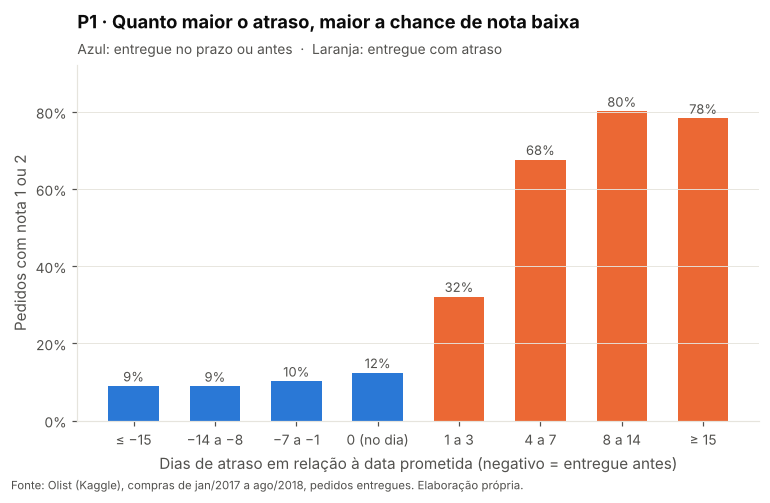

Mann-Whitney (notas dos atrasados < notas dos no prazo): U = 102,644,264; p = 0.0e+00
Qui-quadrado (atraso × nota baixa): χ² = 15,074; p = 0.0e+00
Risco relativo de nota baixa: 62.4% / 9.2% = 6.8×


UFs que mais concentram pedidos atrasados (volume absoluto):
uf   regiao  pedidos  taxa_atraso  atrasados  pct_dos_atrasos
SP  Sudeste    40335         4.50       1815             27.8
RJ  Sudeste    12291        12.16       1495             22.9
MG  Sudeste    11293         4.60        519              8.0
BA Nordeste     3249        12.16        395              6.1
RS      Sul     5310         6.12        325              5.0
SC      Sul     3525         8.26        291              4.5


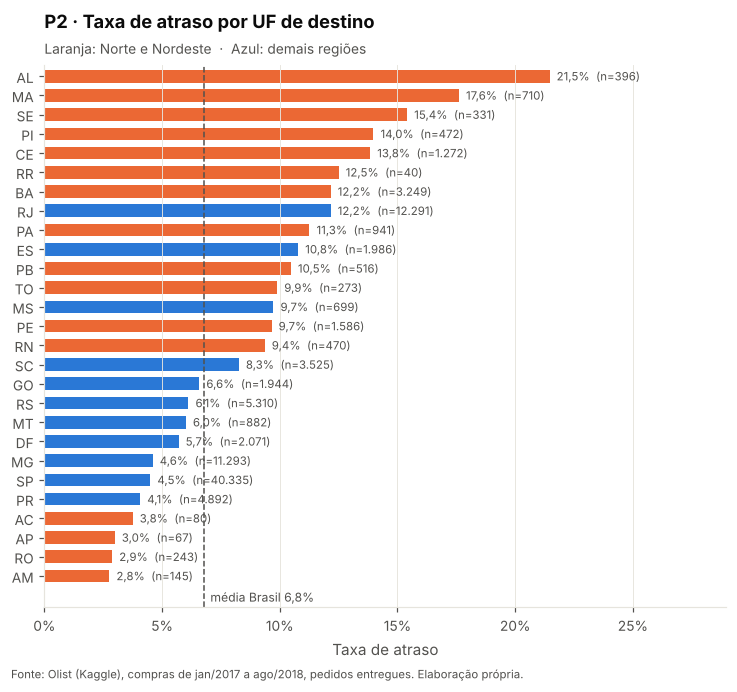

Qui-quadrado (faixa de distância × atraso): χ² = 544; p = 2.4e-116
Spearman (distância × atraso): ρ = 0.070; p = 3.7e-103


Participação da origem (região do vendedor) no total de pedidos:
regiao_vendedor
Sudeste         83.5
Sul             13.4
Centro-Oeste     1.5
Nordeste         1.6
Norte            0.0


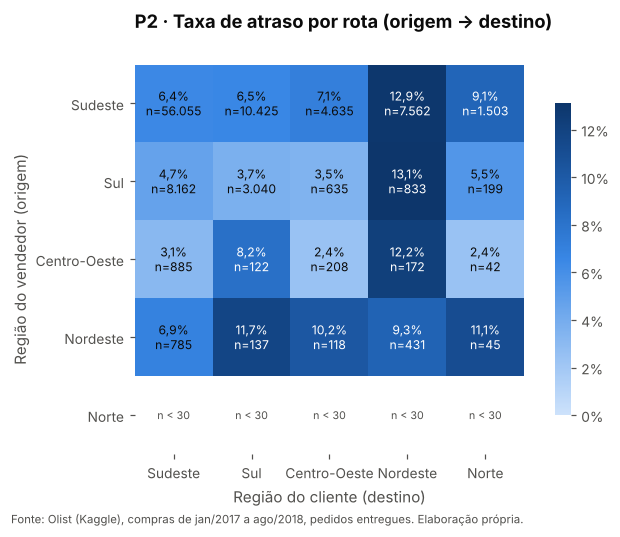

Spearman (volume mensal × taxa de atraso, n = 20 meses): ρ = 0.57; p = 0.009


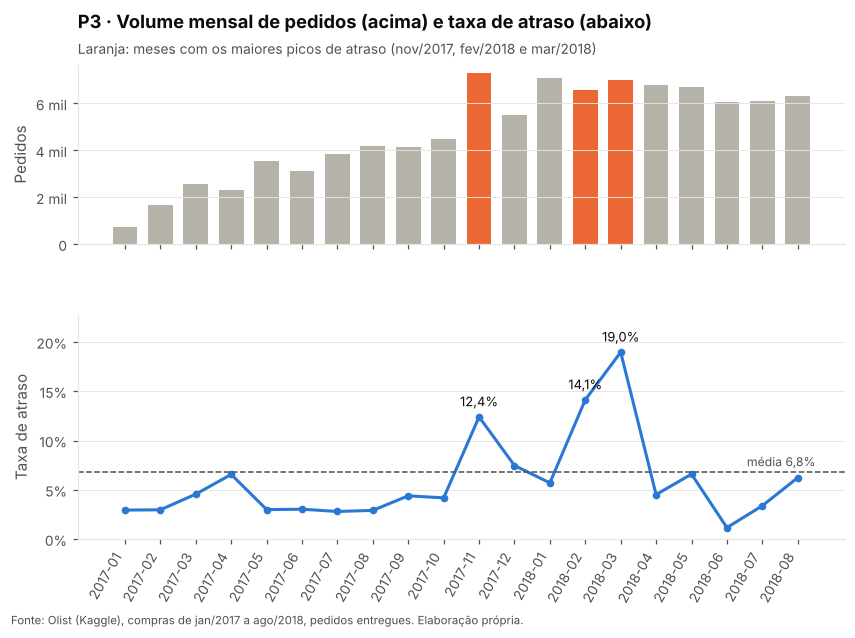

Dias a mais nos pedidos atrasados: postagem +3.0 d | transporte +19.9 d -> o transporte responde por 87% do tempo excedente


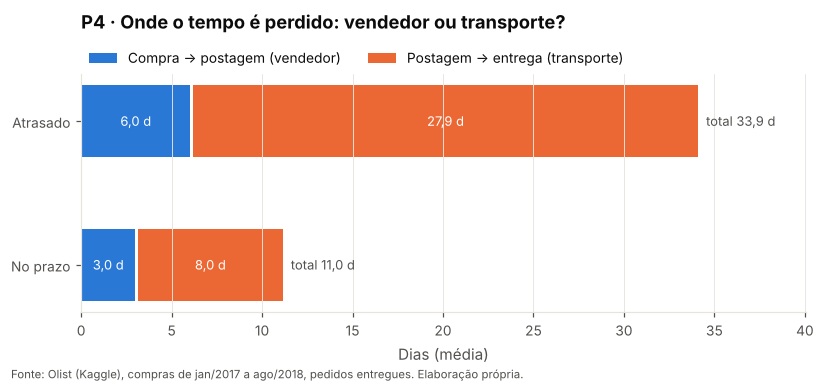

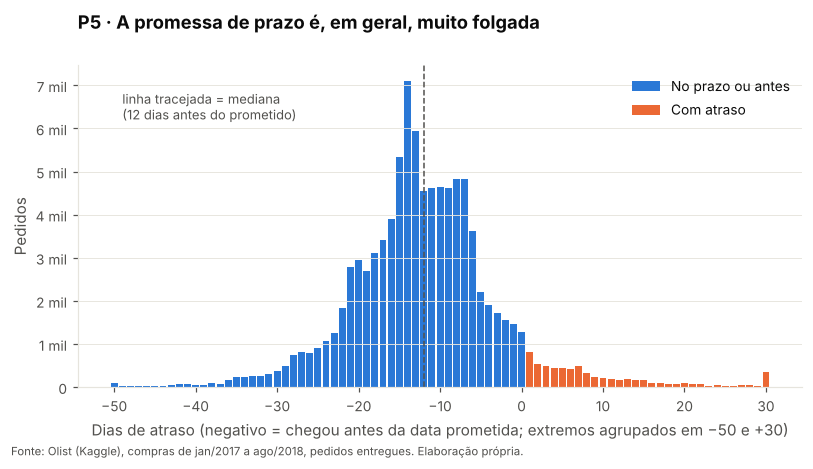

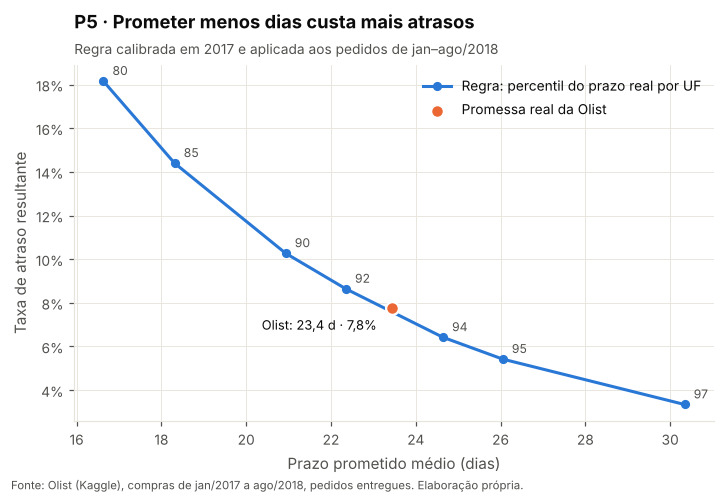

Spearman (folga mediana da UF × taxa de atraso da UF, n = 27): ρ = -0.56; p = 0.003


Treino: 43,407 pedidos (2017) | Teste: 52,612 pedidos (jan–ago/2018)
Regressão logística: 10 maiores coeficientes (variáveis padronizadas; positivo = mais risco)


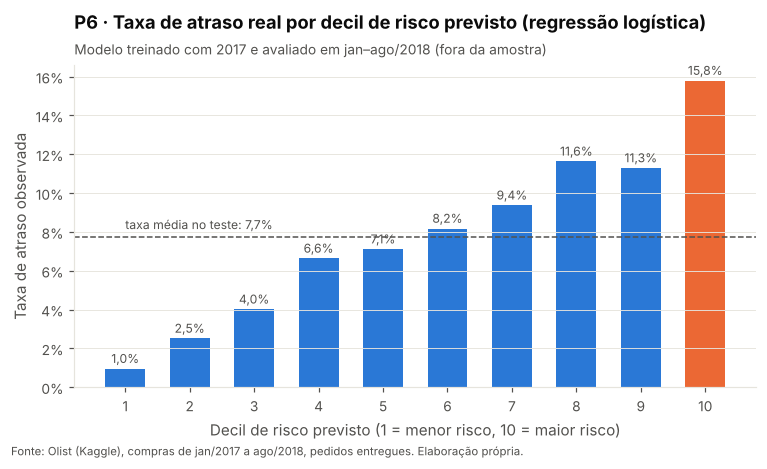

[SUCESSO] 05_analise -> gold.resultados_indicadores | 68 linhas | 1.93s

Pipeline concluído em 4.4 min | run_id 20261109T171607Z-967937


In [2]:
import time
NOTEBOOKS = ["01_coleta", "02_transformacao", "03_carga_gold", "04_qualidade", "05_analise"]
pasta_nb = os.path.join(C.REPO_ROOT, "notebooks")
t0 = time.time()
for nb in NOTEBOOKS:
    print(f"\n\n{'#' * 78}\n# Executando {nb}\n{'#' * 78}")
    get_ipython().run_line_magic("run", f"{pasta_nb}/{nb}.ipynb")
print(f"\nPipeline concluído em {(time.time() - t0) / 60:.1f} min | run_id {C.RUN_ID}")

## Log de execução desta rodada

In [3]:
log = C.read_table(*C.LOG_TABLE)
log.filter(log.run_id == C.RUN_ID).orderBy("inicio_utc").select(
    "etapa", "destino", "linhas", "duracao_s", "status").show(60, truncate=False)

+----------------+-----------------------------+-------+---------+-------+
|etapa           |destino                      |linhas |duracao_s|status |
+----------------+-----------------------------+-------+---------+-------+
|01_coleta       |bronze.orders                |99441  |9.27     |SUCESSO|
|01_coleta       |bronze.customers             |99441  |3.47     |SUCESSO|
|01_coleta       |bronze.order_items           |112650 |2.92     |SUCESSO|
|01_coleta       |bronze.order_payments        |103886 |2.16     |SUCESSO|
|01_coleta       |bronze.order_reviews         |99224  |2.26     |SUCESSO|
|01_coleta       |bronze.products              |32951  |2.22     |SUCESSO|
|01_coleta       |bronze.sellers               |3095   |1.74     |SUCESSO|
|01_coleta       |bronze.geolocation           |1000163|4.22     |SUCESSO|
|01_coleta       |bronze.category_translation  |71     |1.45     |SUCESSO|
|02_transformacao|silver.pedidos               |99441  |3.78     |SUCESSO|
|02_transformacao|silver.

## Evidência de persistência na nuvem
A listagem abaixo mostra a estrutura do lakehouse **no Google Drive**, com o tamanho de cada tabela.
Em seguida aparece o histórico de versões Delta da tabela fato, em que cada carga gera uma nova versão.

In [4]:
def tamanho(p):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs)

print(C.CLOUD_BASE)
for camada in ["raw", "bronze", "silver", "gold", "logs", "evidencias"]:
    base = f"{C.CLOUD_BASE}/{camada}"
    if not os.path.isdir(base):
        continue
    print(f"├── {camada}/  ({tamanho(base) / 1e6:,.1f} MB)")
    for t in sorted(os.listdir(base)):
        p = f"{base}/{t}"
        print(f"│   ├── {t}" + (f"  ({tamanho(p) / 1e6:,.2f} MB)" if os.path.isdir(p) else ""))

/home/claude/mvp_olist_lakehouse
├── raw/  (126.2 MB)
│   ├── manifesto_coleta.json
│   ├── olist  (126.19 MB)
├── bronze/  (65.3 MB)
│   ├── category_translation  (0.01 MB)
│   ├── customers  (7.05 MB)
│   ├── geolocation  (25.84 MB)
│   ├── order_items  (6.85 MB)
│   ├── order_payments  (3.88 MB)
│   ├── order_reviews  (9.60 MB)
│   ├── orders  (10.53 MB)
│   ├── products  (1.38 MB)
│   ├── sellers  (0.14 MB)
├── silver/  (39.9 MB)
│   ├── avaliacoes  (9.50 MB)
│   ├── clientes  (7.05 MB)
│   ├── geolocalizacao_cep  (0.43 MB)
│   ├── itens_pedido  (6.82 MB)
│   ├── pagamentos  (3.86 MB)
│   ├── pedidos  (10.73 MB)
│   ├── produtos  (1.40 MB)
│   ├── vendedores  (0.13 MB)
├── gold/  (16.3 MB)
│   ├── dim_cliente  (7.90 MB)
│   ├── dim_produto  (1.57 MB)
│   ├── dim_tempo  (0.02 MB)
│   ├── dim_vendedor  (0.20 MB)
│   ├── dq_conformidade_catalogo  (0.01 MB)
│   ├── dq_perfil_atributos  (0.01 MB)
│   ├── fato_pedido  (6.58 MB)
│   ├── resultados_indicadores  (0.01 MB)
├── logs/  (0.2 MB

In [5]:
C.table_history("gold", "fato_pedido").select("version", "timestamp", "operation", "operationMetrics.numOutputRows").show(truncate=False)

+-------+-----------------------+---------+-------------+
|version|timestamp              |operation|numOutputRows|
+-------+-----------------------+---------+-------------+
|0      |2026-11-09 17:18:41.425|WRITE    |99441        |
+-------+-----------------------+---------+-------------+

